# MedLens: exploring the FAERS dataset (2015–2025)

**Hackcessibility, Information Access track**

This notebook works from the cleaned dataset `fda_adverse_events_2015_2026_CLEAN.csv`. It needs **no internet and no API key**. It covers:

1. what's in the dataset, and what it can't tell us
2. how reporting spikes show that **reports aren't risk**
3. who the reports are about, and how serious they were
4. a two-medicine comparison with the **population lens** (age and sex)
5. which problems stand out for a medicine (PRR signal)
6. exports: charts for the slides, and a `medlens_data.json` file that powers the MedLens Streamlit app (`app.py`) offline

> **This shows reports, not risk.** FAERS reports are unverified and can't tell anyone how likely a side effect is. Don't use this to make medical decisions.

**How to run:** Put the CSV in the same folder as this notebook (or in a `data/` subfolder), then use *Kernel → Restart & Run All*. Loading 528,000 rows takes about 10 seconds. In Google Colab, upload the CSV to the session's Files panel first.

## 1. Setup and loading
Change the two medicines here. The search checks both the suspect-drug name and the brand name, so `"adalimumab"` and `"humira"` both work.

In [1]:
# If anything is missing, uncomment and run:
# %pip install pandas matplotlib ipywidgets

import json, re
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, MaxNLocator, NullFormatter, PercentFormatter

# ---- Settings you can change ----
DRUG_A = "adalimumab"    # Humira
DRUG_B = "etanercept"    # Enbrel: same drug class (TNF blockers), used for the same conditions
EXPORT_DIR = Path("exports")
CSV_NAME = "fda_adverse_events_2015_2026_CLEAN.csv"

FIGS, TABLES = {}, {}    # everything worth exporting is collected here (section 9)

In [2]:
# Chart style: one color per medicine (colorblind-safe pair), a separate color for whole-dataset charts.
COLOR_A, COLOR_B = "#2a78d6", "#eb6834"
COLOR_ALL = "#6250d6"
INK, INK_2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ_BLUE = LinearSegmentedColormap.from_list("medlens_blue", BLUE_RAMP)

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
    "font.family": "sans-serif", "font.size": 10.5,
})

In [3]:
candidates = [Path(CSV_NAME), Path("data") / CSV_NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Put {CSV_NAME} in the same folder as this notebook, or in a data/ subfolder.")

df = pd.read_csv(DATA_PATH, low_memory=False)

# --- Cleaning ---
# Apostrophes were mangled to "^S" in the export ("Crohn^S Disease"): put them back.
for col in ["reactions", "primary_reaction", "drug_indication", "suspect_drug", "brand_name", "manufacturer", "pharm_class"]:
    df[col] = df[col].str.replace(r"\^[sS]\b", "'s", regex=True)

df["receive_date"] = pd.to_datetime(df["receive_date"])

# Route codes are the standard E2B route codes used in FAERS.
ROUTES = {"48.0": "Oral", "58.0": "Under the skin (injection)", "42.0": "Intravenous", "41.0": "Intravenous",
          "40.0": "Intravenous", "30.0": "Into a muscle (injection)", "64.0": "Exposure during pregnancy",
          "55.0": "Inhaled", "61.0": "On the skin", "62.0": "Skin patch", "15.0": "Intrauterine device",
          "47.0": "Eye", "45.0": "Nasal", "37.0": "Spinal (intrathecal)", "67.0": "Vaginal",
          "65.0": "Not recorded", "Unknown": "Not recorded"}
df["route"] = df["drug_route"].map(ROUTES).fillna("Other")

AGE_LABELS = {"Infant(0-2)": "0–2", "Child(3-12)": "3–12", "Teen(13-18)": "13–18", "Adult(19-40)": "19–40",
              "Middle-Aged(41-65)": "41–65", "Senior(66-80)": "66–80", "Elderly(81+)": "81+", "Unknown": "Not recorded"}
AGES = list(AGE_LABELS.values())
df["age"] = pd.Categorical(df["age_group"].map(AGE_LABELS), categories=AGES, ordered=True)
df["sex"] = df["patient_sex"].replace({"Unknown": "Not recorded"})
SEXES = ["Female", "Male", "Not recorded"]

UNKNOWN_INDICATION = {"Unknown", "Product Used For Unknown Indication"}
df["indication"] = df["drug_indication"].where(~df["drug_indication"].isin(UNKNOWN_INDICATION), "Not recorded")
df["serious_bool"] = df["serious"].eq("Yes")
df["drug_key"] = df["suspect_drug"].str.split("; ").str[0]          # first name listed for the suspect drug
SEARCH_TEXT = (df["suspect_drug"] + " | " + df["brand_name"]).str.upper()

# Long table: one row per (report, reaction). The CSV lists up to 5 reactions per report.
_rx = df["reactions"].str.split("; ").explode()
RX = pd.DataFrame({"row": _rx.index.values, "reaction": _rx.values}).drop_duplicates()
REACTION_TOTALS = RX["reaction"].value_counts()
N = len(df)

print(f"Loaded {N:,} reports from {DATA_PATH} ({df.receive_date.min():%b %Y} to {df.receive_date.max():%b %Y})")
print(f"{df.drug_key.nunique():,} suspect drugs · {REACTION_TOTALS.size:,} different reaction terms · {len(RX):,} report–reaction pairs")

Loaded 528,000 reports from data/fda_adverse_events_2015_2026_CLEAN.csv (Jan 2015 to Dec 2025)
9,633 suspect drugs · 13,940 different reaction terms · 1,751,842 report–reaction pairs


In [4]:
# Report entries that describe how a medicine was used (or an exposure), not a health problem.
NOT_HEALTH = re.compile("^(" + "|".join([
    "drug ineffective( for unapproved indication)?", "off label use", "no adverse event", "treatment failure",
    "therapeutic (response|product effect) (decreased|incomplete|unexpected)", "drug effect (decreased|incomplete)",
    "inappropriate schedule of .*", "wrong technique .*", "wrong (drug|product) administered", "incorrect dose administered",
    "intentional product .*", ".*dose omission.*", "product .*", "expired product administered", "drug administered .*",
    "accidental exposure to product.*", "medication error", "device .*", "maternal exposure.*", "exposure during pregnancy",
    "foetal exposure.*", "treatment noncompliance", "underdose", "inappropriate .*", "intercepted .*",
]) + ")$", re.IGNORECASE)

# Plain-language names for common MedDRA terms (the official terms use British spelling).
PLAIN = {
    "abdominal discomfort": "Stomach discomfort", "abdominal pain": "Stomach pain", "abdominal pain upper": "Upper stomach pain",
    "acute kidney injury": "Sudden kidney damage", "acute myocardial infarction": "Heart attack (acute)", "alopecia": "Hair loss",
    "anaemia": "Anemia", "arthralgia": "Joint pain", "asthenia": "Weakness", "cardiac failure congestive": "Congestive heart failure",
    "cerebrovascular accident": "Stroke", "condition aggravated": "Condition got worse", "confusional state": "Confusion",
    "coronary artery disease": "Coronary artery disease", "decreased appetite": "Less appetite", "diarrhoea": "Diarrhea",
    "drug hypersensitivity": "Allergic reaction to a medicine", "dyspnoea": "Shortness of breath", "epistaxis": "Nosebleed",
    "erythema": "Skin redness", "gastrointestinal haemorrhage": "Bleeding in the digestive tract", "gynaecomastia": "Breast growth in males",
    "haematuria": "Blood in urine", "haemorrhage": "Bleeding", "hyperhidrosis": "Heavy sweating", "hypersensitivity": "Allergic reaction",
    "hypertension": "High blood pressure", "hypoaesthesia": "Numbness", "hypoglycaemia": "Low blood sugar",
    "hypotension": "Low blood pressure", "injection site pain": "Pain where the shot was given", "insomnia": "Trouble sleeping",
    "malaise": "Feeling unwell", "myalgia": "Muscle pain", "myocardial infarction": "Heart attack", "nasopharyngitis": "Common cold",
    "oedema peripheral": "Swelling in the legs or arms", "pain in extremity": "Pain in an arm or leg", "paraesthesia": "Tingling",
    "pruritus": "Itching", "pyrexia": "Fever", "rectal haemorrhage": "Rectal bleeding", "renal failure": "Kidney failure",
    "somnolence": "Sleepiness", "syncope": "Fainting", "tachycardia": "Fast heart rate", "upper gastrointestinal haemorrhage":
    "Upper digestive tract bleeding", "urticaria": "Hives", "vision blurred": "Blurry vision", "weight decreased": "Weight loss",
    "weight increased": "Weight gain", "abnormal weight gain": "Abnormal weight gain", "hyperprolactinaemia": "High prolactin (a hormone)",
    "injection site erythema": "Redness where the shot was given", "injection site swelling": "Swelling where the shot was given",
    "arthropathy": "Joint disease", "intestinal obstruction": "Blocked intestine", "osteoarthritis": "Osteoarthritis (joint wear)",
    "pneumonia": "Pneumonia (lung infection)", "fall": "Fall", "back pain": "Back pain", "bladder cancer": "Bladder cancer",
}


def plain(term: str) -> str:
    return PLAIN.get(str(term).lower(), str(term)[:1].upper() + str(term)[1:])


def show(df_, pct=(), ints=(), dec=()):
    """Display a table with readable number formats."""
    out = df_.copy()
    for c in pct:
        out[c] = out[c].map(lambda v: "—" if pd.isna(v) else f"{v:.1%}")
    for c in ints:
        out[c] = out[c].map(lambda v: "—" if pd.isna(v) else f"{int(v):,}")
    for c in dec:
        out[c] = out[c].map(lambda v: "—" if pd.isna(v) else f"{v:.2f}")
    display(out)


@lru_cache(maxsize=None)
def drug_mask(name: str) -> pd.Series:
    """Reports whose suspect drug (generic or brand name) contains `name`."""
    m = SEARCH_TEXT.str.contains(name.upper(), regex=False)
    if not m.any():
        raise ValueError(f"No reports with suspect drug {name!r}. Try another spelling, a generic name, or a brand name.")
    return m


def pop_mask(age="Any", sex="Any") -> np.ndarray:
    m = np.ones(N, dtype=bool)
    if age != "Any":
        m &= (df["age"] == age).values
    if sex != "Any":
        m &= (df["sex"] == sex).values
    return m


def who(age="Any", sex="Any") -> str:
    noun = {"Any": "people", "Female": "female patients", "Male": "male patients", "Not recorded": "people with no recorded sex"}[sex]
    if age == "Any":
        return f"{noun} of any age"
    return f"{noun} with no recorded age" if age == "Not recorded" else f"{noun} aged {age}"


def reaction_shares(mask) -> tuple:
    """For a set of reports: number and share of reports that list each reaction."""
    mask = np.asarray(mask)
    n = int(mask.sum())
    c = RX.loc[mask[RX["row"].values], "reaction"].value_counts()
    return pd.DataFrame({"reports": c, "share": c / n if n else 0.0}), n

In [5]:
def grouped_barh(data, title, xlabel, pct=True, note=None, colors=(COLOR_A, COLOR_B), legend_labels=None, value_labels=False):
    """Horizontal grouped bars: rows of `data` are categories (top to bottom), columns are series."""
    data = data.fillna(0)
    cats = list(data.index)[::-1]
    y = np.arange(len(cats))
    k = data.shape[1]
    h = 0.8 / max(k, 2)
    fig, ax = plt.subplots(figsize=(9, 0.3 * len(cats) * max(k, 1.6) + 1.5))
    for i, col in enumerate(data.columns):
        offset = (k - 1) / 2 * h - i * h
        vals = data[col].values[::-1]
        ax.barh(y + offset, vals, height=h - 0.04, color=colors[i], label=(legend_labels or list(data.columns))[i])
        if value_labels:
            for yy, v in zip(y + offset, vals):
                ax.annotate(f"{v:.1%}" if pct else f"{v:,.0f}", (v, yy), xytext=(4, 0), textcoords="offset points",
                            va="center", fontsize=9, color=INK_2)
    ax.set_yticks(y, cats)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0) if pct else FuncFormatter(lambda v, _: f"{v:,.0f}"))
    if value_labels:
        ax.set_xlim(0, data.values.max() * 1.15)
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=26 if k > 1 else 6)
    if k > 1:   # legend sits under the title, never on top of the bars
        ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=k, borderaxespad=0.2, handlelength=1.2)
    if note:
        fig.text(0.01, 0.005, note, fontsize=8.5, color=INK_2, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.05 if note else 0, 1, 1))
    return fig, ax

## 2. What's in the dataset, and what it can't tell us

Check the structure before charting anything. Three facts shape **every** analysis in this notebook:

In [6]:
per_month = df.groupby([df.receive_date.dt.year, df.receive_date.dt.month]).size()
listed = df["reactions"].str.count("; ") + 1
facts = pd.Series({
    "Reports": f"{N:,}",
    "Date range": f"{df.receive_date.min():%Y-%m-%d} to {df.receive_date.max():%Y-%m-%d}",
    "Reports per month": f"{per_month.min():,} to {per_month.max():,}  (fixed: this is a sample)",
    "Suspect drugs per report": "1 (name variants of one drug are joined with ';')",
    "Reactions listed per report": f"1 to {listed.max()}  ({(listed < df.num_reactions).mean():.0%} of reports had more than are listed)",
    "Reports from the US": f"{df.country.eq('US').mean():.0%}",
    "Reports marked serious": f"{df.serious_bool.mean():.0%}",
}, name="")
display(facts.to_frame())

,
Reports,"528,000"
Date range,2015-01-01 to 2025-12-31
Reports per month,"4,000 to 4,000 (fixed: this is a sample)"
Suspect drugs per report,1 (name variants of one drug are joined with ';')
Reactions listed per report,1 to 5 (34% of reports had more than are listed)
Reports from the US,60%
Reports marked serious,75%


**What this means for MedLens:**

- **It's a sample with exactly 4,000 reports a month.** Totals over time are flat by design, so we never chart raw counts over time. We use **shares**, such as "what % of 2020's reports were about drug X".
- **Each report names one suspected drug.** That fixes the API problem from the first notebook, where a drug could be listed only because the person also took it.
- **At most 5 reactions are listed per report.** A third of reports had more. Reaction shares here are a floor, and they favor whatever was listed first.

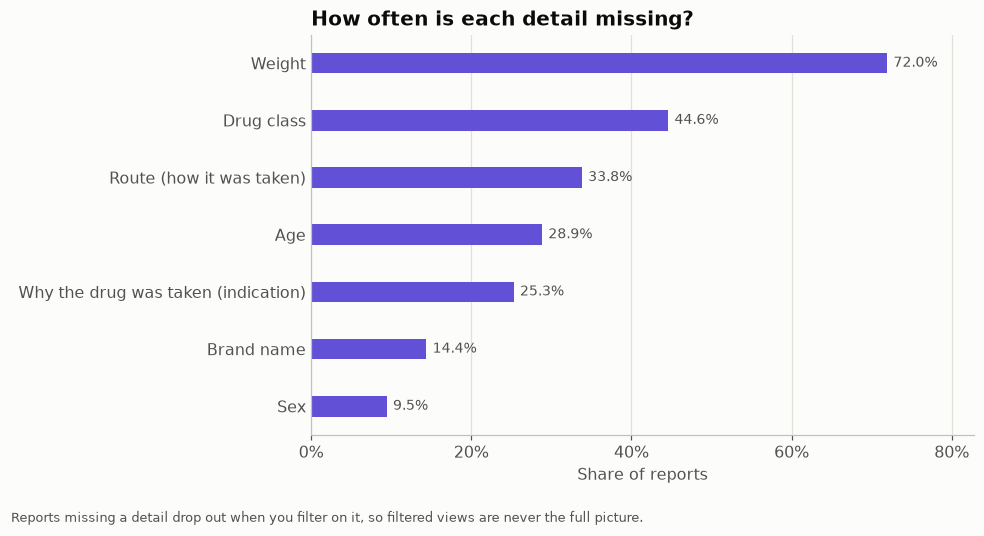

In [7]:
missing = pd.Series({
    "Weight": df.patient_weight_kg.isna().mean(),
    "Drug class": df.pharm_class.eq("Unknown").mean(),
    "Age": df.age.eq("Not recorded").mean(),
    "Why the drug was taken (indication)": df.indication.eq("Not recorded").mean(),
    "Route (how it was taken)": df.route.eq("Not recorded").mean(),
    "Brand name": df.brand_name.eq("Unknown").mean(),
    "Sex": df.sex.eq("Not recorded").mean(),
}).sort_values(ascending=False)
TABLES["missing_fields"] = missing.to_frame("share missing")

fig, ax = grouped_barh(missing.to_frame("missing"), "How often is each detail missing?", "Share of reports",
                       colors=(COLOR_ALL,), value_labels=True,
                       note="Reports missing a detail drop out when you filter on it, so filtered views are never the full picture.")
FIGS["missing_fields"] = fig
plt.show()

## 3. Reports aren't risk: the reporting spikes

Because the sample holds steady at 4,000 reports a month, a drug's **share of each year's reports** shows when reporting about it surged. Look for one-year jumps where one drug suddenly takes up a big slice of all reports.

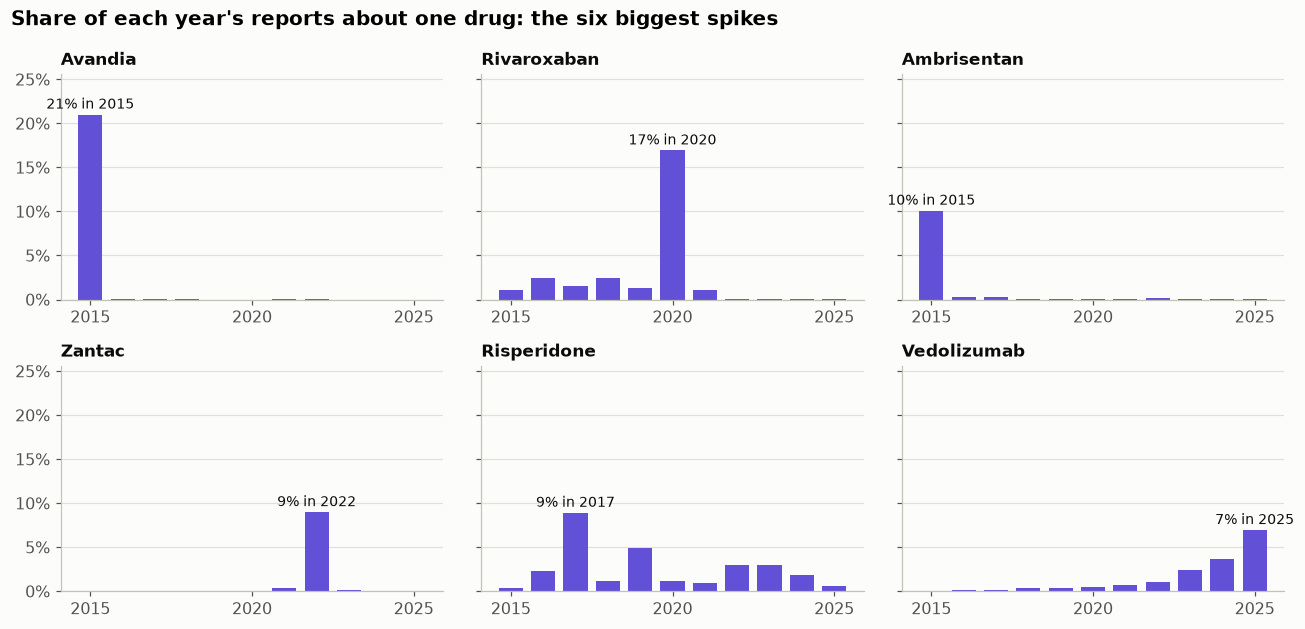

In [8]:
year_share = pd.crosstab(df["drug_key"], df["year"], normalize="columns")
spikiest = year_share.max(axis=1).sort_values(ascending=False).head(6).index
TABLES["drug_share_by_year"] = year_share.loc[spikiest]

fig, axes = plt.subplots(2, 3, figsize=(12, 5.8), sharey=True)
axes[0, 0].set_ylim(0, year_share.loc[spikiest].values.max() * 1.22)   # room for the labels
for ax, drug in zip(axes.flat, spikiest):
    s = year_share.loc[drug]
    ax.bar(s.index, s.values, color=COLOR_ALL, width=0.75)
    peak = s.idxmax()
    ax.annotate(f"{s.max():.0%} in {peak}", (peak, s.max()), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
    ax.set_title(drug.title(), fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xticks([2015, 2020, 2025])
    ax.grid(axis="x", visible=False)
fig.suptitle("Share of each year's reports about one drug: the six biggest spikes", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
FIGS["reporting_spikes"] = fig
plt.show()

What do the spike years look like up close? Each row below is one drug's busiest year.

In [9]:
def spike_profile(drug):
    yr = int(year_share.loc[drug].idxmax())
    m = (df["drug_key"] == drug) & (df["year"] == yr)
    shares, n = reaction_shares(m.values)
    shares = shares[~shares.index.str.match(NOT_HEALTH)]
    months = df.loc[m, "month"].value_counts(normalize=True)
    return {
        "drug": drug.title(), "year": yr, "reports": n, "share of year": year_share.loc[drug, yr],
        "top problem": f"{plain(shares.index[0])} ({shares.share.iloc[0]:.0%})",
        "busiest month": f"{months.max():.0%} of the year's reports",
        "US": df.loc[m, "country"].eq("US").mean(),
        "sex not recorded": df.loc[m, "sex"].eq("Not recorded").mean(),
        "male": df.loc[m, "sex"].eq("Male").mean(),
    }


spikes = pd.DataFrame([spike_profile(d) for d in spikiest]).set_index("drug")
TABLES["spike_profiles"] = spikes
show(spikes, pct=["share of year", "US", "sex not recorded", "male"], ints=["reports"])

,year,reports,share of year,top problem,busiest month,US,sex not recorded,male
drug,,,,,,,,
Avandia,2015,"10,077",21.0%,Heart attack (45%),35% of the year's reports,100.0%,41.1%,34.5%
Rivaroxaban,2020,"8,124",16.9%,Bleeding in the digestive tract (37%),11% of the year's reports,99.6%,0.1%,52.0%
Ambrisentan,2015,"4,838",10.1%,Shortness of breath (15%),78% of the year's reports,99.7%,0.3%,22.6%
Zantac,2022,"4,307",9.0%,Bladder cancer (10%),29% of the year's reports,99.8%,1.5%,60.1%
Risperidone,2017,"4,273",8.9%,Breast growth in males (91%),44% of the year's reports,98.5%,1.6%,97.5%
Vedolizumab,2025,"3,332",6.9%,Crohn's disease (29%),13% of the year's reports,9.6%,0.1%,41.0%


**How to read this.** Several of these spikes share the marks of **stimulated reporting**:

- the reports arrive in a burst, often packed into a few months
- they come almost entirely from the US
- they're dominated by one problem

Bulk reports like these often come in during product-liability lawsuits (Avandia, Xarelto, Risperdal, and Zantac were all the subject of large US lawsuits). Reports can also surge after news coverage or a new warning.

Not every rise is a burst, though. Vedolizumab's grew steadily, mostly from outside the US, which looks more like growing use plus company follow-up programs.

The drug didn't suddenly become more dangerous. More reports were *filed*. This is the clearest evidence for the MedLens message that **report counts measure reporting, not risk.**

## 4. Who are the reports about, and how serious were they?

,reports,serious,hospitalized,fatal,share of reports
age,,,,,
0–2,"3,101",90.3%,42.2%,12.8%,0.6%
3–12,"9,767",67.8%,32.5%,5.9%,1.8%
13–18,"8,617",72.6%,35.9%,6.1%,1.6%
19–40,"53,277",79.5%,35.2%,6.6%,10.1%
41–65,"166,278",78.3%,38.7%,8.6%,31.5%
66–80,"108,781",79.1%,46.8%,15.7%,20.6%
81+,"25,842",81.1%,52.5%,25.2%,4.9%
Not recorded,"152,337",65.5%,21.6%,7.5%,28.9%


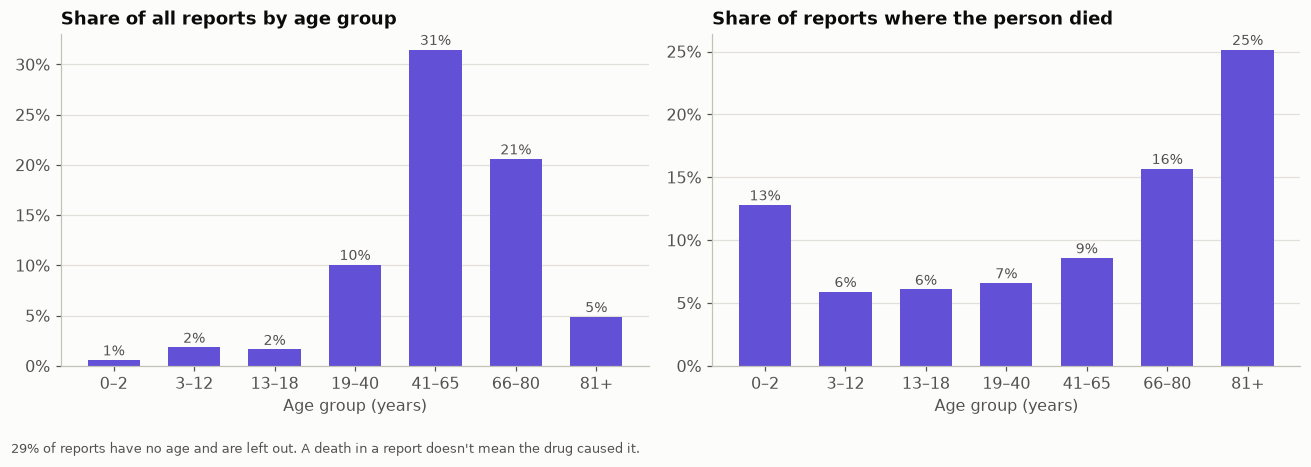

In [10]:
by_age = df.groupby("age", observed=False).agg(
    reports=("report_id", "size"), serious=("serious_bool", "mean"),
    hospitalized=("is_hospitalized", "mean"), fatal=("is_fatal", "mean"))
by_age["share of reports"] = by_age.reports / N
TABLES["seriousness_by_age"] = by_age
show(by_age, pct=["serious", "hospitalized", "fatal", "share of reports"], ints=["reports"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
known = by_age.drop(index="Not recorded")
for ax, col, title in ((axes[0], "share of reports", "Share of all reports by age group"),
                       (axes[1], "fatal", "Share of reports where the person died")):
    ax.bar(known.index.astype(str), known[col], color=COLOR_ALL, width=0.65)
    for x, v in enumerate(known[col]):
        ax.annotate(f"{v:.0%}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("Age group (years)")
    ax.set_title(title, fontsize=12)
fig.text(0.01, 0.005, f"{by_age.loc['Not recorded', 'share of reports']:.0%} of reports have no age and are left out. "
         "A death in a report doesn't mean the drug caused it.", fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.05, 1, 1))
FIGS["age_and_fatal"] = fig
plt.show()

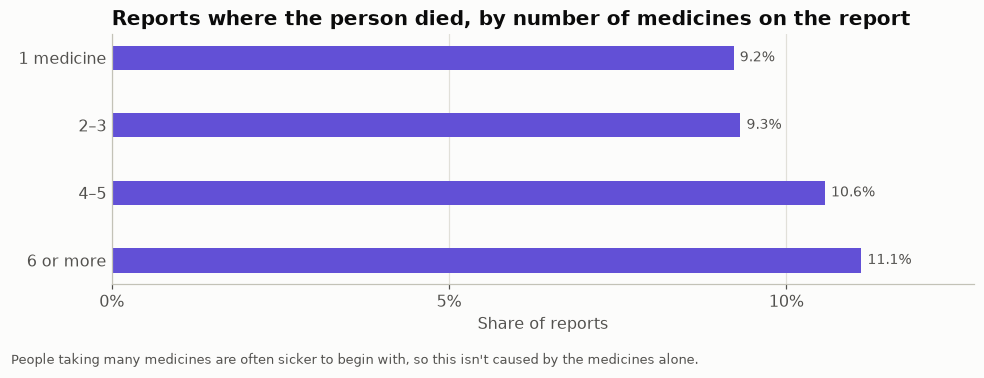

In [11]:
POLY_ORDER = ["Single", "2-3 Drugs", "4-5 Drugs", "Polypharmacy(6+)"]
poly = (df[df.drug_count_category.isin(POLY_ORDER)]
        .groupby("drug_count_category")
        .agg(reports=("report_id", "size"), serious=("serious_bool", "mean"), fatal=("is_fatal", "mean"))
        .reindex(POLY_ORDER))
poly.index = ["1 medicine", "2–3", "4–5", "6 or more"]
TABLES["seriousness_by_number_of_medicines"] = poly

fig, ax = grouped_barh(poly[["fatal"]], "Reports where the person died, by number of medicines on the report",
                       "Share of reports", colors=(COLOR_ALL,), value_labels=True,
                       note="People taking many medicines are often sicker to begin with, so this isn't caused by the medicines alone.")
FIGS["fatal_by_number_of_medicines"] = fig
plt.show()

## 5. Comparing two medicines

The default pair is **adalimumab (Humira) vs etanercept (Enbrel)**. Both are TNF blockers used for rheumatoid arthritis, psoriasis and similar conditions. Comparing drugs used for the *same* conditions is fairer, because their patients are more alike.

To compare other drugs, change `DRUG_A` and `DRUG_B` in section 1. Some popular drugs have few reports in this sample (for example, about 1,500 for ibuprofen and 400 for naproxen). Run the next cell to see the most-reported options.

In [12]:
popular = df["drug_key"].value_counts().head(40)
print("Most-reported suspect drugs in this dataset:")
print(", ".join(f"{d.lower()} ({n:,})" for d, n in popular.items()))

Most-reported suspect drugs in this dataset:
tofacitinib (13,807), risperidone (13,487), rivaroxaban (12,968), avandia (10,091), etanercept (8,751), adalimumab (8,394), dupilumab (8,246), sodium oxybate (8,008), vedolizumab (7,875), pregabalin (7,845), certolizumab pegol (6,528), palbociclib (6,103), secukinumab (6,072), fingolimod hcl (5,664), ambrisentan (5,282), infliximab-dyyb (4,953), infliximab (4,733), nivolumab (4,572), zantac (4,561), lenalidomide (4,539), tenofovir disoproxil fumarate (4,426), rituximab (4,316), enzalutamide (4,304), ocrelizumab (3,752), omalizumab (3,669), abatacept (3,601), human immunoglobulin g (3,492), pimavanserin tartrate (3,364), natalizumab (3,212), teriflunomide (3,106), esomeprazole magnesium (2,948), dimethyl fumarate (2,916), ruxolitinib (2,794), evolocumab (2,781), tocilizumab (2,717), dalfampridine (2,690), mirabegron (2,676), insulin glargine (2,522), apremilast (2,516), docetaxel (2,499)


In [13]:
A, B = drug_mask(DRUG_A).values, drug_mask(DRUG_B).values


def profile(name, m):
    sub = df[m]
    return pd.Series({
        "Reports in dataset": len(sub),
        "Female": sub.sex.eq("Female").mean(), "Male": sub.sex.eq("Male").mean(),
        "Sex not recorded": sub.sex.eq("Not recorded").mean(),
        "Age not recorded": sub.age.eq("Not recorded").mean(),
        "Median age": sub.patient_age_years.median(),
        "Serious": sub.serious_bool.mean(), "Hospitalized": sub.is_hospitalized.mean(),
        "Life-threatening": sub.is_life_threat.mean(), "Died": sub.is_fatal.mean(),
        "Recovered (at time of report)": sub.patient_recovered.mean(),
        "Median medicines on report": sub.num_drugs.median(),
        "Most common reason taken": sub.indication[sub.indication != "Not recorded"].value_counts().index[0],
        "From the US": sub.country.eq("US").mean(),
    }, name=name)


prof = pd.DataFrame([profile(DRUG_A, A), profile(DRUG_B, B)]).T
TABLES["drug_profiles"] = prof
pct_rows = ["Female", "Male", "Sex not recorded", "Age not recorded", "Serious", "Hospitalized",
            "Life-threatening", "Died", "Recovered (at time of report)", "From the US"]
pretty = prof.copy().astype(object)
for r in pct_rows:
    pretty.loc[r] = [f"{v:.1%}" for v in prof.loc[r]]
pretty.loc["Reports in dataset"] = [f"{int(v):,}" for v in prof.loc["Reports in dataset"]]
pretty.loc["Median age"] = [f"{v:.0f}" for v in prof.loc["Median age"]]
pretty.loc["Median medicines on report"] = [f"{v:.0f}" for v in prof.loc["Median medicines on report"]]
display(pretty)

,adalimumab,etanercept
Reports in dataset,"8,642","8,752"
Female,63.0%,74.6%
Male,33.6%,24.7%
Sex not recorded,3.4%,0.7%
Age not recorded,33.9%,8.9%
Median age,56,59
Serious,86.6%,62.3%
Hospitalized,46.4%,19.2%
Life-threatening,2.4%,1.7%
Died,4.6%,2.7%


**Careful with differences like "Serious" or "Died".** They reflect *who sent the reports* as much as the drugs. For the default pair, adalimumab's reports come more often from outside the US and leave age blank far more often, which points to different reporting sources. A gap here is a question to ask, not an answer.

### Who are each medicine's reports about?
This is why a population lens matters: the two medicines' reports come from different groups of people.

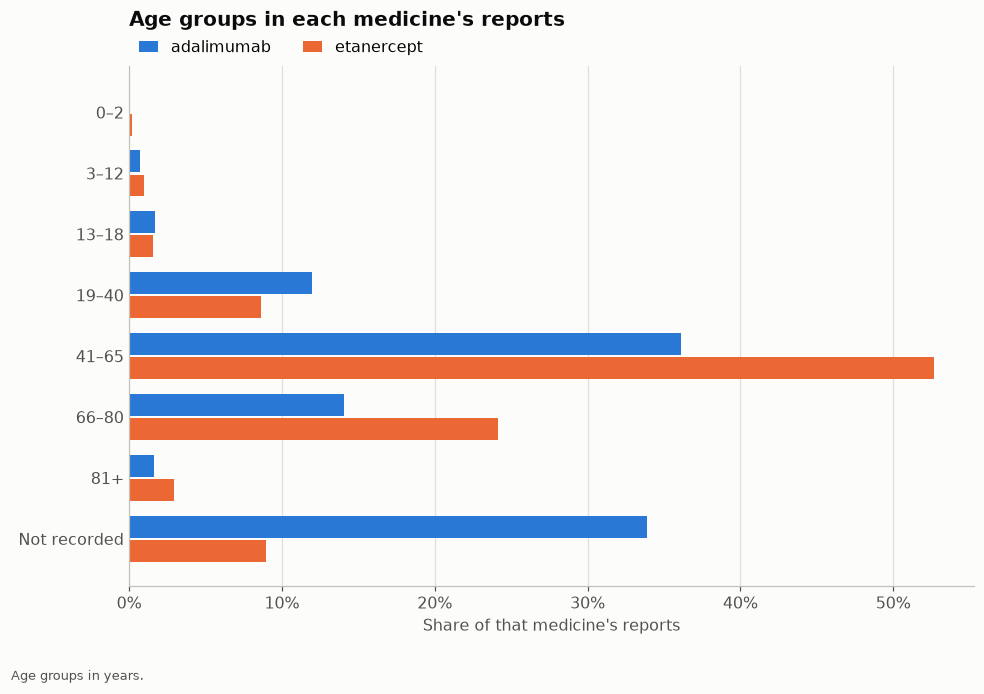

In [14]:
age_mix = pd.DataFrame({
    DRUG_A: df.loc[A, "age"].value_counts(normalize=True).reindex(AGES),
    DRUG_B: df.loc[B, "age"].value_counts(normalize=True).reindex(AGES),
})
TABLES["age_mix"] = age_mix
fig, ax = grouped_barh(age_mix, "Age groups in each medicine's reports", "Share of that medicine's reports",
                       note="Age groups in years.")
FIGS["age_mix"] = fig
plt.show()

### What problems were reported?

Each bar shows the **share of that medicine's reports** listing the problem. Problems marked **(condition treated)** match the reason the drug was taken. That's *confounding by indication*: people taking an arthritis drug report arthritis. It's a classic way report data misleads.

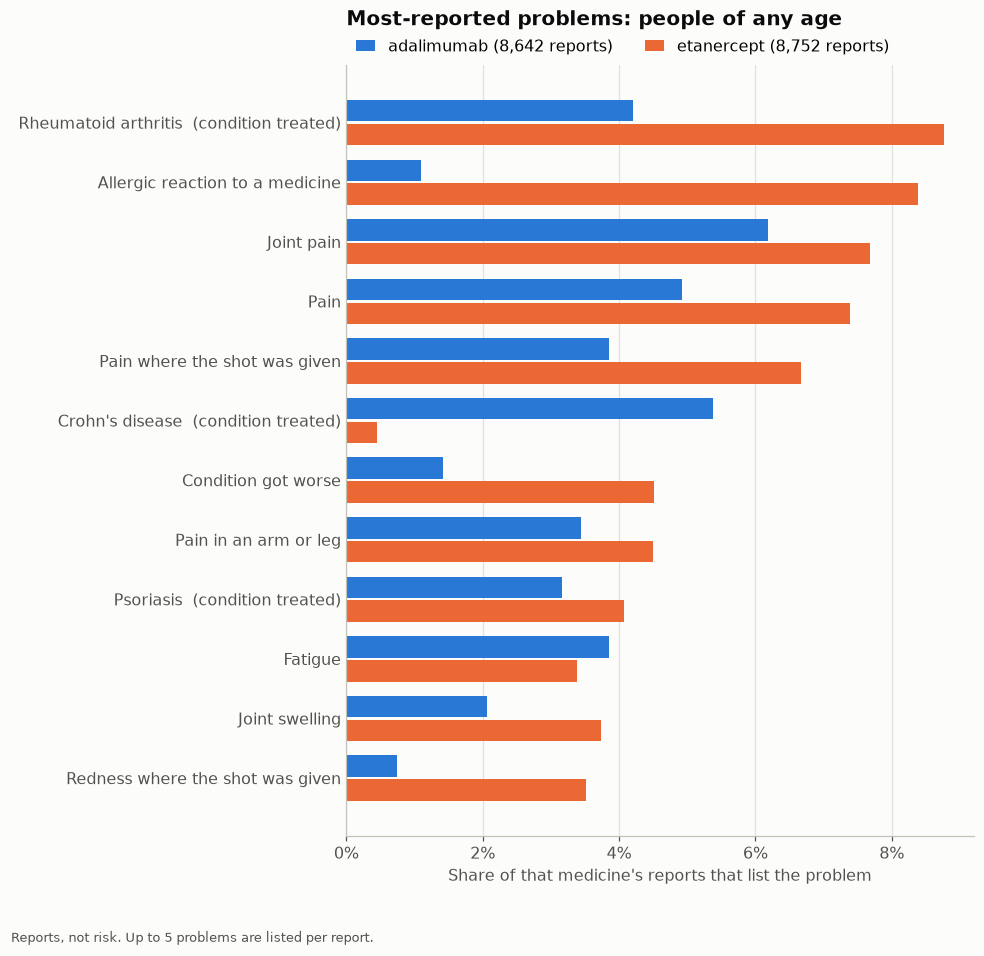

Summary / alt text: For people of any age, there are 8,642 reports with adalimumab as the suspected drug and 8,752 with etanercept; the most-listed problem was joint pain for adalimumab (6%) and rheumatoid arthritis (a condition these drugs treat) for etanercept (9%).


In [15]:
def treated_conditions(m, top=25):
    ind = df.loc[m, "indication"]
    return {s.lower() for s in ind[ind != "Not recorded"].value_counts().head(top).index}


def label(term, treated):
    return plain(term) + ("  (condition treated)" if term.lower() in treated else "")


TREATED = treated_conditions(A) | treated_conditions(B)


def compare(age="Any", sex="Any", top=12, hide_non_health=True):
    pm = pop_mask(age, sex)
    sa, na = reaction_shares(A & pm)
    sb, nb = reaction_shares(B & pm)
    t = pd.DataFrame({f"{DRUG_A} reports": sa.reports, f"{DRUG_A} share": sa.share,
                      f"{DRUG_B} reports": sb.reports, f"{DRUG_B} share": sb.share}).fillna(0)
    if hide_non_health:
        t = t[~t.index.str.match(NOT_HEALTH)]
    t = t.loc[t[[f"{DRUG_A} share", f"{DRUG_B} share"]].max(axis=1).sort_values(ascending=False).index[:top]]
    t.insert(0, "problem", [label(x, TREATED) for x in t.index])
    return t, na, nb


def plot_compare(t, na, nb, age="Any", sex="Any", key=None):
    shares = t.set_index("problem")[[f"{DRUG_A} share", f"{DRUG_B} share"]]
    fig, ax = grouped_barh(
        shares, f"Most-reported problems: {who(age, sex)}", "Share of that medicine's reports that list the problem",
        legend_labels=[f"{DRUG_A} ({na:,} reports)", f"{DRUG_B} ({nb:,} reports)"],
        note="Reports, not risk. Up to 5 problems are listed per report.")
    if key:
        FIGS[key] = fig
    plt.show()
    clean = lambda x: x.replace("  (condition treated)", " (a condition these drugs treat)").lower()
    ta, tb = clean(shares.iloc[:, 0].idxmax()), clean(shares.iloc[:, 1].idxmax())
    sa, sb = shares.iloc[:, 0].max(), shares.iloc[:, 1].max()
    if ta == tb:
        most = f"{ta} was listed most for both ({sa:.0%} and {sb:.0%} of reports)"
    else:
        most = f"the most-listed problem was {ta} for {DRUG_A} ({sa:.0%}) and {tb} for {DRUG_B} ({sb:.0%})"
    print(f"Summary / alt text: For {who(age, sex)}, there are {na:,} reports with {DRUG_A} as the suspected drug "
          f"and {nb:,} with {DRUG_B}; {most}.")


cmp_all, na, nb = compare()
TABLES["compare_all"] = cmp_all
plot_compare(cmp_all, na, nb, key="compare_all")

## 6. The population lens

The same comparison for a chosen group of people. The heatmaps show each problem's share of reports **within each age group**, using one color scale for both medicines so they can be compared. Age groups with fewer than 100 reports are left out, because their percentages jump around too much.

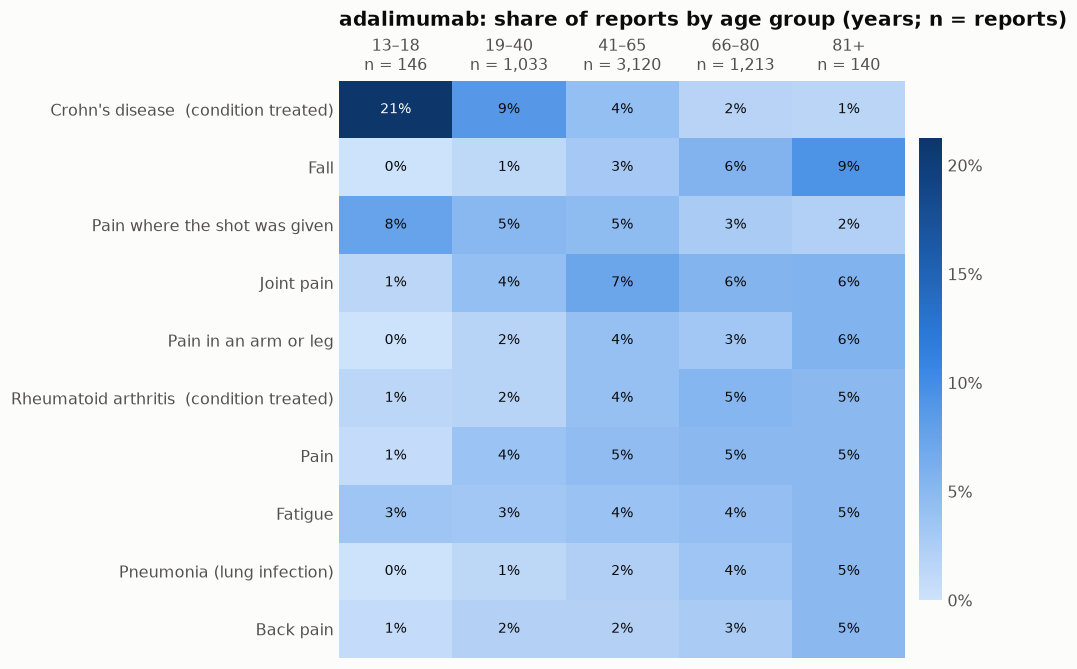

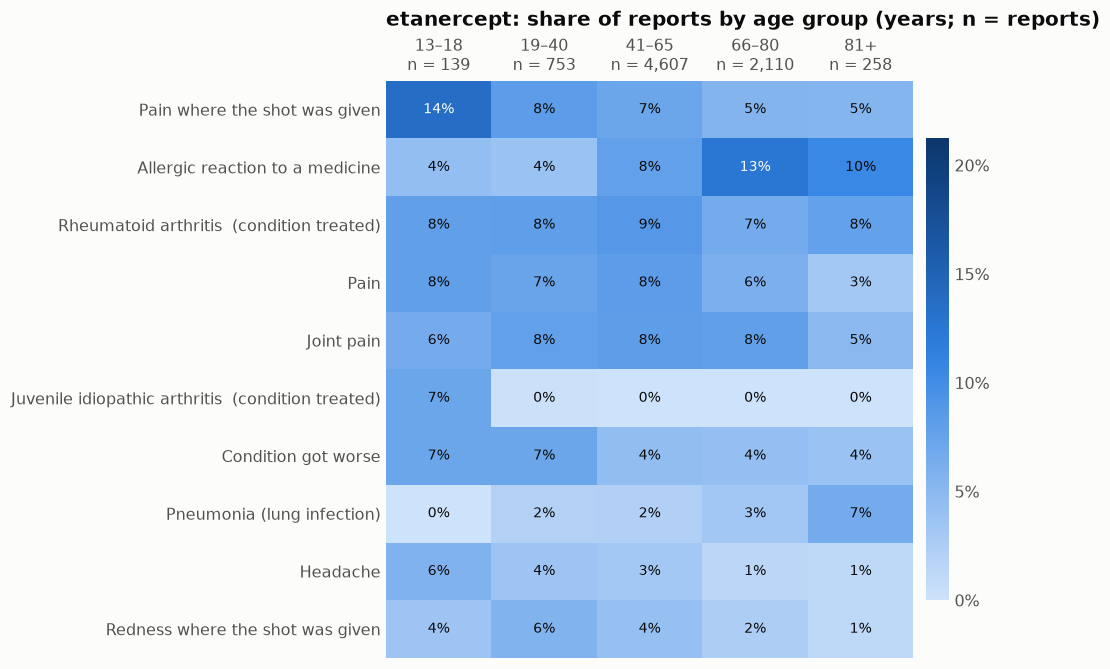

In [16]:
LENS_AGES = ["13–18", "19–40", "41–65", "66–80", "81+"]


def lens_grid(m, top=10, min_reports=100):
    cols, ns = {}, {}
    for g in LENS_AGES:
        s, n = reaction_shares(m & pop_mask(g))
        if n >= min_reports:
            cols[g], ns[g] = s["share"], n
    grid = pd.DataFrame(cols).fillna(0)
    grid = grid[~grid.index.str.match(NOT_HEALTH)]
    return grid.loc[grid.max(axis=1).sort_values(ascending=False).index[:top]], ns


def heatmap(grid, ns, name, vmax, key=None):
    fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(grid) + 2.0))
    im = ax.imshow(grid.values, cmap=SEQ_BLUE, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(grid.shape[1]), [f"{c}\nn = {ns[c]:,}" for c in grid.columns])
    ax.set_yticks(range(len(grid)), [label(t, TREATED) for t in grid.index])
    ax.tick_params(length=0)
    ax.xaxis.tick_top()
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.5 * vmax else INK)
    ax.set_title(f"{name}: share of reports by age group (years; n = reports)", pad=36)
    cb = fig.colorbar(im, ax=ax, format=PercentFormatter(1.0, decimals=0), shrink=0.8, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    cb.ax.tick_params(length=0, colors=INK_2)
    fig.tight_layout()
    if key:
        FIGS[key] = fig
    plt.show()


grid_a, ns_a = lens_grid(A)
grid_b, ns_b = lens_grid(B)
vmax = float(max(grid_a.values.max(), grid_b.values.max()))
heatmap(grid_a, ns_a, DRUG_A, vmax, key="lens_heatmap_a")
heatmap(grid_b, ns_b, DRUG_B, vmax, key="lens_heatmap_b")
TABLES["lens_grid_a"], TABLES["lens_grid_b"] = grid_a, grid_b

### Try it: the interactive lens
Pick an age group and sex to redraw the comparison. The dropdowns need a live kernel. If you're viewing a saved copy, the fixed example below shows one combination.

In [17]:
try:
    import ipywidgets as widgets

    @widgets.interact(age=["Any"] + AGES, sex=["Any"] + SEXES,
                      top=widgets.IntSlider(value=12, min=5, max=25, continuous_update=False))
    def lens(age="66–80", sex="Female", top=12):
        t, na, nb = compare(age, sex, top)
        if min(na, nb) < 30:
            print(f"Too few reports for {who(age, sex)} ({na} and {nb}). Pick a wider group.")
            return
        plot_compare(t, na, nb, age, sex)
except ImportError:
    print("For the interactive version: %pip install ipywidgets")

interactive(children=(Dropdown(description='age', index=6, options=('Any', '0–2', '3–12', '13–18', '19–40', '4…

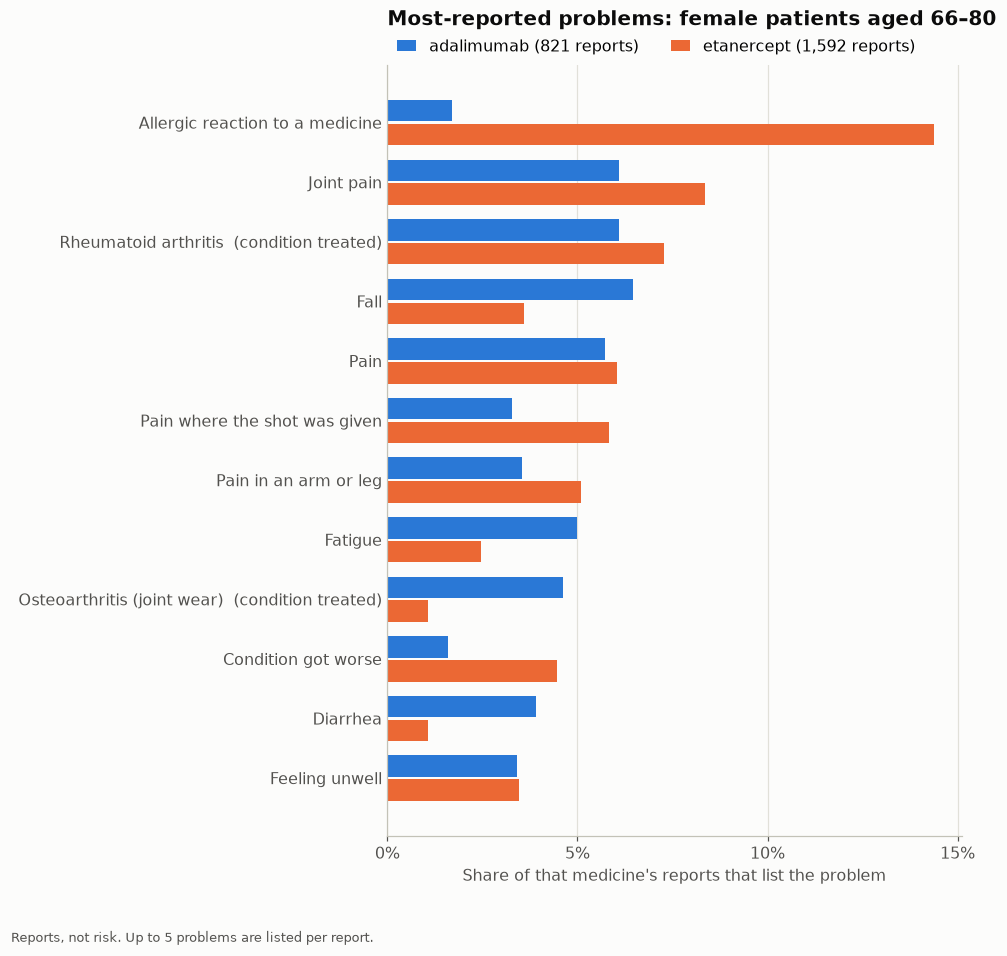

Summary / alt text: For female patients aged 66–80, there are 821 reports with adalimumab as the suspected drug and 1,592 with etanercept; the most-listed problem was fall for adalimumab (6%) and allergic reaction to a medicine for etanercept (14%).


In [18]:
cmp_f66, na_f66, nb_f66 = compare("66–80", "Female")
TABLES["compare_female_66_80"] = cmp_f66
plot_compare(cmp_f66, na_f66, nb_f66, "66–80", "Female", key="compare_female_66_80")

## 7. Which problems stand out? The PRR signal

**PRR (proportional reporting ratio)** compares how often a problem is listed for this medicine with how often it's listed for every other medicine in the dataset:

$$\text{PRR} = \frac{\text{share of this medicine's reports listing the problem}}{\text{share of all other reports listing it}}$$

PRR = 1 means the problem is listed as often as for other medicines. A common screening rule flags PRR ≥ 2 with at least 3 reports. Here we also require the 95% confidence interval to sit above 1.

A high PRR is **a signal worth a closer look**. It isn't a risk, and it isn't proof. Spikes like the ones in section 3 also distort it: the Avandia burst makes heart attacks look common in "all other reports".

,reports,PRR,CI low,CI high,stands out
problem,,,,,
Osteoarthritis (joint wear) (condition treated),300,15.28,13.48,17.31,True
Blocked intestine,232,9.41,8.21,10.79,True
Crohn's disease (condition treated),465,7.89,7.18,8.67,True
Psoriasis (condition treated),273,5.24,4.64,5.92,True
Pain where the shot was given,333,4.82,4.32,5.38,True
Rheumatoid arthritis (condition treated),363,4.68,4.22,5.20,True
Joint pain,534,2.91,2.68,3.17,True
Pain in an arm or leg,297,2.37,2.11,2.66,True
Stomach pain,200,2.14,1.87,2.47,True


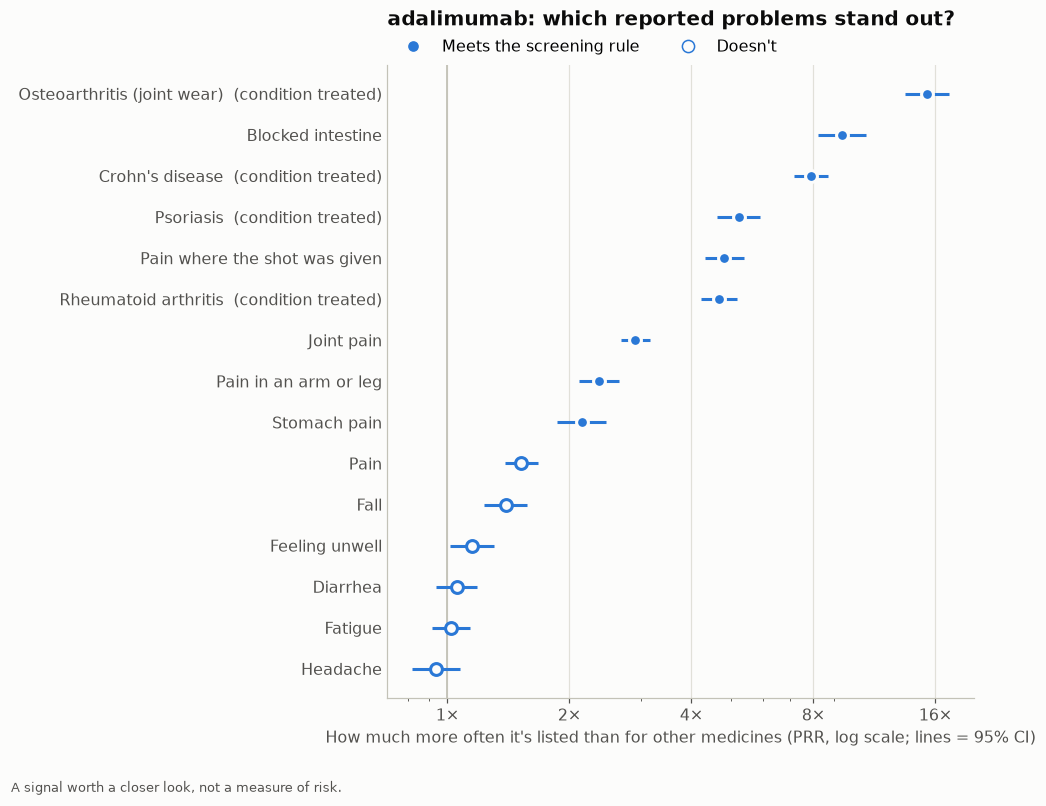

Alt text: Dot plot of PRR for adalimumab's most-listed problems. Meeting the screening rule: Osteoarthritis (joint wear) (condition treated), Blocked intestine, Crohn's disease (condition treated), Psoriasis (condition treated), Pain where the shot was given, Rheumatoid arthritis (condition treated), Joint pain, Pain in an arm or leg, Stomach pain.



,reports,PRR,CI low,CI high,stands out
problem,,,,,
Redness where the shot was given,308,16.84,14.87,19.08,True
Rheumatoid arthritis (condition treated),767,10.69,9.93,11.51,True
Pain where the shot was given,583,8.87,8.16,9.66,True
Psoriasis (condition treated),356,6.93,6.22,7.72,True
Joint swelling,327,6.19,5.54,6.93,True
Joint disease,228,5.96,5.21,6.82,True
Allergic reaction to a medicine,734,5.08,4.73,5.47,True
Joint pain,672,3.66,3.40,3.95,True
Pain in an arm or leg,394,3.14,2.85,3.47,True


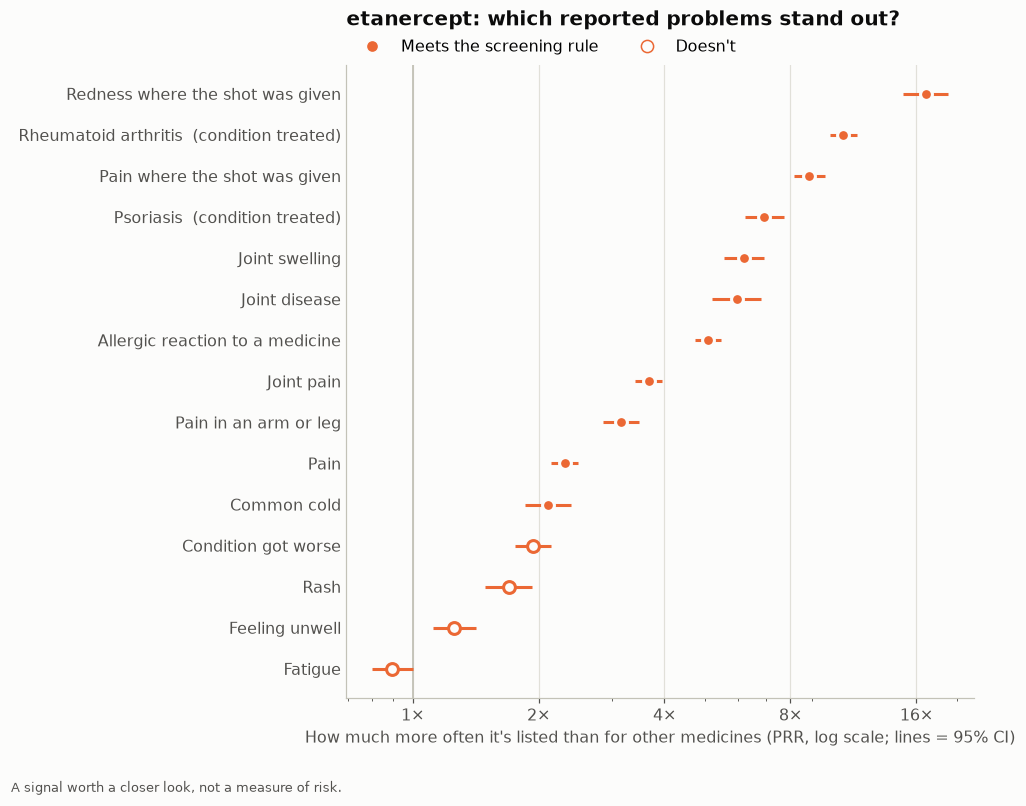

Alt text: Dot plot of PRR for etanercept's most-listed problems. Meeting the screening rule: Redness where the shot was given, Rheumatoid arthritis (condition treated), Pain where the shot was given, Psoriasis (condition treated), Joint swelling, Joint disease, Allergic reaction to a medicine, Joint pain, Pain in an arm or leg, Pain, Common cold.



In [19]:
def prr_table(m, top=15):
    n_drug = int(m.sum())
    other = N - n_drug
    s, _ = reaction_shares(m)
    s = s[~s.index.str.match(NOT_HEALTH)].head(top)
    a = s["reports"]
    c = REACTION_TOTALS.reindex(a.index) - a
    keep = (a > 0) & (c > 0)
    a, c = a[keep], c[keep]
    prr = (a / n_drug) / (c / other)
    se = np.sqrt(1 / a - 1 / n_drug + 1 / c - 1 / other)
    out = pd.DataFrame({"reports": a, "PRR": prr, "CI low": np.exp(np.log(prr) - 1.96 * se),
                        "CI high": np.exp(np.log(prr) + 1.96 * se)})
    out["stands out"] = (out.PRR >= 2) & (out.reports >= 3) & (out["CI low"] > 1)
    out.insert(0, "problem", [label(t, TREATED) for t in out.index])
    return out.sort_values("PRR", ascending=False)


def plot_prr(d, name, color, key=None):
    d = d.iloc[::-1]
    y = np.arange(len(d))
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(d) + 1.6))
    ax.hlines(y, d["CI low"], d["CI high"], color=color, lw=2)
    flagged = d["stands out"].values
    ax.scatter(d["PRR"][flagged], y[flagged], s=60, color=color, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.scatter(d["PRR"][~flagged], y[~flagged], s=60, facecolor=SURFACE, edgecolor=color, linewidth=2, zorder=3)
    ax.axvline(1, color=AXIS, lw=1.2, zorder=1)
    ax.set_xscale("log")
    lo, hi = min(d["CI low"].min(), 0.9) / 1.15, max(d["CI high"].max(), 2.2) * 1.15
    ax.set_xlim(lo, hi)
    ax.xaxis.set_major_locator(FixedLocator([t for t in (0.1, 0.25, 0.5, 1, 2, 4, 8, 16, 32, 64, 128) if lo <= t <= hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_yticks(y, d["problem"])
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("How much more often it's listed than for other medicines (PRR, log scale; lines = 95% CI)")
    ax.set_title(f"{name}: which reported problems stand out?", pad=26)
    ax.legend(handles=[
        Line2D([], [], marker="o", ls="", ms=8, color=color, markeredgecolor=SURFACE, label="Meets the screening rule"),
        Line2D([], [], marker="o", ls="", ms=8, markerfacecolor=SURFACE, markeredgecolor=color, label="Doesn't"),
    ], loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
    fig.text(0.01, 0.005, "A signal worth a closer look, not a measure of risk.", fontsize=8.5, color=INK_2)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    if key:
        FIGS[key] = fig
    plt.show()


for name, m, color in ((DRUG_A, A, COLOR_A), (DRUG_B, B, COLOR_B)):
    prr = prr_table(m)
    TABLES[f"prr_{name}"] = prr
    show(prr.set_index("problem"), ints=["reports"], dec=["PRR", "CI low", "CI high"])
    plot_prr(prr, name, color, key=f"prr_{name}")
    flagged = prr.loc[prr["stands out"], "problem"].str.replace("  (", " (", regex=False).tolist()
    print(f"Alt text: Dot plot of PRR for {name}'s most-listed problems. "
          f"Meeting the screening rule: {', '.join(flagged) if flagged else 'none'}.\n")

## 8. Pitch numbers

These are the key numbers from this run, worded so you can paste them into slides. Re-run after changing the medicines.

In [20]:
pa, pb = prof[DRUG_A], prof[DRUG_B]
top_spike = spikes.iloc[0]
lines = [
    f"The dataset holds {N:,} FDA adverse-event reports from 2015–2025 (a sample of 4,000 a month).",
    f"{missing['Age']:.0%} of reports don't record age and {missing['Sex']:.0%} don't record sex, so every filtered view leaves people out.",
    f"In {top_spike.name}'s busiest year ({top_spike.year}), it made up {top_spike['share of year']:.0%} of ALL reports, "
    f"{top_spike['US']:.0%} of them from the US. That's a burst of reporting, not a sudden change in safety.",
    f"Reports where the person died: {by_age.loc['81+', 'fatal']:.0%} for ages 81+ vs {by_age.loc['19–40', 'fatal']:.0%} for ages 19–40.",
    f"{DRUG_A}: {int(pa['Reports in dataset']):,} reports, {pa['Female']:.0%} female, median age {pa['Median age']:.0f}. "
    f"{DRUG_B}: {int(pb['Reports in dataset']):,} reports, {pb['Female']:.0%} female, median age {pb['Median age']:.0f}.",
]
treated_rows = cmp_all[cmp_all.problem.str.contains("condition treated")]
if len(treated_rows):
    lines.append(f"{len(treated_rows)} of the top {len(cmp_all)} 'side effects' are actually conditions these drugs treat "
                 f"(e.g. {treated_rows.problem.iloc[0].replace('  (condition treated)', '').lower()}).")
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}\n")

1. The dataset holds 528,000 FDA adverse-event reports from 2015–2025 (a sample of 4,000 a month).

2. 29% of reports don't record age and 9% don't record sex, so every filtered view leaves people out.

3. In Avandia's busiest year (2015), it made up 21% of ALL reports, 100% of them from the US. That's a burst of reporting, not a sudden change in safety.

4. Reports where the person died: 25% for ages 81+ vs 7% for ages 19–40.

5. adalimumab: 8,642 reports, 63% female, median age 56. etanercept: 8,752 reports, 75% female, median age 59.

6. 3 of the top 12 'side effects' are actually conditions these drugs treat (e.g. rheumatoid arthritis).



## 9. Export for the slides and the web app

This section saves:

- **PNG charts and CSV tables** to `exports/`
- **`exports/medlens_data.json`**, the data file for the MedLens Streamlit app (`app.py`). It covers the 150 most-reported drugs. For each one it holds:
  - the top problems for every age group × sex (groups with fewer than 20 reports are left out)
  - a profile: who the reports are about and how serious they were
  - the conditions it's taken for, so the app can flag "side effects" that are really the illness
  - PRR for its most-listed problems (section 7) and its share of each year's reports (section 3)

  It also holds plain-language names for the medical terms, the missing-data shares, and the biggest reporting spikes. The app loads this one file, so it works offline with no API key and no rate limits.

In [21]:
EXPORT_DIR.mkdir(exist_ok=True)
for key, fig in FIGS.items():
    fig.savefig(EXPORT_DIR / f"{key}.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
for key, table in TABLES.items():
    table.to_csv(EXPORT_DIR / f"{key}.csv")
print(f"Saved {len(FIGS)} charts and {len(TABLES)} tables to {EXPORT_DIR.resolve()}")

Saved 11 charts and 13 tables to /mnt/c/Users/kenji/Downloads/MedLens_streamlit/medlens/exports


In [22]:
def _num(v, nd=4):
    """JSON-safe number: a rounded float, or None when it's missing."""
    if v is None or pd.isna(v):
        return None
    return round(float(v), nd)


def build_app_data(n_drugs=150, top_health=25, top_other=5, min_reports=20, n_prr=15):
    """Summarize the most-reported drugs for the MedLens Streamlit app (app.py).

    For each drug: a profile, the conditions it's taken for, its share of each year's reports,
    PRR for its most-listed problems (section 7), and its top problems for every age group x sex.
    """
    top_drugs = df["drug_key"].value_counts().head(n_drugs).index
    rx = RX.merge(df[["drug_key", "age", "sex"]], left_on="row", right_index=True)
    rx = rx[rx.drug_key.isin(top_drugs)]
    base = df[df.drug_key.isin(top_drugs)]
    health = {t: not NOT_HEALTH.match(t) for t in REACTION_TOTALS.index}
    used_terms = set()

    def top_terms(reactions):
        counts = reactions.value_counts()
        is_health = counts.index.map(lambda t: health.get(t, True)).values.astype(bool)
        top = pd.concat([counts[is_health].head(top_health), counts[~is_health].head(top_other)])
        top = top.sort_values(ascending=False)
        used_terms.update(top.index)
        return [[t, int(c)] for t, c in top.items()]

    out = {}
    for drug in top_drugs:
        d_rows, d_rx = base[base.drug_key == drug], rx[rx.drug_key == drug]
        n_drug = len(d_rows)

        # Top problems for every age group x sex (the population lens)
        groups = {}
        for age in ["Any"] + AGES:
            for sex in ["Any"] + SEXES:
                rm = np.ones(len(d_rows), bool)
                xm = np.ones(len(d_rx), bool)
                if age != "Any":
                    rm &= (d_rows.age == age).values
                    xm &= (d_rx.age == age).values
                if sex != "Any":
                    rm &= (d_rows.sex == sex).values
                    xm &= (d_rx.sex == sex).values
                n = int(rm.sum())
                if n < min_reports:
                    continue
                groups[f"{age}|{sex}"] = {"n": n, "top": top_terms(d_rx.loc[xm, "reaction"])}

        # Who the reports are about, and how serious they were (section 5)
        reasons = d_rows.indication[d_rows.indication != "Not recorded"].value_counts()
        profile = {
            "reports": n_drug,
            "female": _num(d_rows.sex.eq("Female").mean()),
            "male": _num(d_rows.sex.eq("Male").mean()),
            "sex_not_recorded": _num(d_rows.sex.eq("Not recorded").mean()),
            "age_not_recorded": _num(d_rows.age.eq("Not recorded").mean()),
            "median_age": _num(d_rows.patient_age_years.median(), 1),
            "serious": _num(d_rows.serious_bool.mean()),
            "hospitalized": _num(d_rows.is_hospitalized.mean()),
            "life_threatening": _num(d_rows.is_life_threat.mean()),
            "died": _num(d_rows.is_fatal.mean()),
            "recovered": _num(d_rows.patient_recovered.mean()),
            "from_us": _num(d_rows.country.eq("US").mean()),
            "median_medicines": _num(d_rows.num_drugs.median(), 1),
            "top_reasons": [plain(t) for t in reasons.head(3).index],
        }

        # PRR for the most-listed health problems, against every other report (section 7)
        a = d_rx["reaction"].value_counts()
        a = a[[health.get(t, True) for t in a.index]].head(n_prr)
        c = REACTION_TOTALS.reindex(a.index) - a
        keep = (a > 0) & (c > 0)
        a, c = a[keep], c[keep]
        other = N - n_drug
        prr = (a / n_drug) / (c / other)
        se = np.sqrt(1 / a - 1 / n_drug + 1 / c - 1 / other)
        low, high = np.exp(np.log(prr) - 1.96 * se), np.exp(np.log(prr) + 1.96 * se)
        prr_rows = [{"term": t, "reports": int(a[t]), "prr": _num(prr[t], 3), "low": _num(low[t], 3),
                     "high": _num(high[t], 3), "flag": bool(prr[t] >= 2 and a[t] >= 3 and low[t] > 1)}
                    for t in a.index]
        used_terms.update(a.index)

        brands = d_rows.brand_name[d_rows.brand_name != "Unknown"].value_counts().head(3).index.tolist()
        out[drug] = {
            "label": drug.lower(),
            "brands": brands,
            "profile": profile,
            "treated": sorted({s.lower() for s in reasons.head(25).index}),
            "year_share": {str(int(y)): _num(v, 5) for y, v in year_share.loc[drug].items()},
            "prr": prr_rows,
            "groups": groups,
        }

    per_month = df.groupby([df.receive_date.dt.year, df.receive_date.dt.month]).size()
    listed = df["reactions"].str.count("; ") + 1
    return {
        "meta": {
            "version": 2,
            "source": "FAERS sample, 4,000 reports per month, 2015–2025",
            "source_url": "https://www.kaggle.com/datasets/kanchana1990/fda-drug-adverse-event-reports-2015-to-2026-faers",
            "reports": N,
            "date_from": f"{df.receive_date.min():%Y-%m-%d}",
            "date_to": f"{df.receive_date.max():%Y-%m-%d}",
            "per_month": [int(per_month.min()), int(per_month.max())],
            "max_listed": int(listed.max()),
            "more_than_listed": _num((listed < df.num_reactions).mean()),
            "from_us": _num(df.country.eq("US").mean()),
            "serious": _num(df.serious_bool.mean()),
            "missing": {k: _num(v) for k, v in missing.items()},
            "spikes": [{"drug": d, "year": int(r["year"]), "reports": int(r["reports"]),
                        "share": _num(r["share of year"]), "from_us": _num(r["US"]), "top_problem": r["top problem"]}
                       for d, r in spikes.iterrows()],
            "note": "Counts are reports that list the problem (up to 5 per report). Reports, not risk.",
            "ages": AGES,
            "sexes": SEXES,
            "min_reports": min_reports,
            "top_health": top_health,
            "terms": {t: {"plain": plain(t), "health": bool(health.get(t, True))} for t in sorted(used_terms)},
        },
        "drugs": out,
    }


app_data = build_app_data()
path = EXPORT_DIR / "medlens_data.json"
path.write_text(json.dumps(app_data, separators=(",", ":")))
print(f"Wrote {path} ({path.stat().st_size / 1e6:.1f} MB) with {len(app_data['drugs'])} drugs")
print("Start the web app from this folder with:  streamlit run app.py")

Wrote exports/medlens_data.json (2.6 MB) with 150 drugs
Start the web app from this folder with:  streamlit run app.py


### Open the web app

From a terminal in this folder (the one with `app.py`):

```
pip install -r requirements.txt
streamlit run app.py
```

The app opens at http://localhost:8501 and reads `exports/medlens_data.json`. Re-run this notebook whenever you change the data, then refresh the app.

## 10. Takeaways

- **Use shares, not counts.** Counts in this sample are fixed by design, and in real FAERS they mostly reflect how popular a drug is and how much reporting is going on.
- **Show the missing data.** Age and sex are often blank, and the web app should say so up front.
- **Spikes are about reporting.** A single drug can take up a fifth of a year's reports during a reporting burst.
- **Watch for the condition being treated.** Many top "side effects" are the disease itself.
- **PRR is a signal, not a verdict.** If the app shows it, it needs plain words and a caveat.